# 04 · Detector-level Shack–Hartmann: spots, noise and centroids

A real Shack–Hartmann sensor does not measure slopes directly: each lenslet forms a diffraction spot on a few detector pixels, and the slope is inferred from the spot's centre of gravity. This notebook builds that chain with `shwfs_detector.py`: lenslet spot → finite detector window → photon and read noise → centroid → response matrix.

**Checks against theory:** a phase ramp moves the spot by the amount the Fourier shift theorem predicts, and the centroid noise matches the analytic photon-noise and read-noise formulas.

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
FIGURES = ROOT / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

from reconstruction import residual_wavefront, rms, subaperture_masks, synthesize_from_coefficients
from shwfs_detector import (
    add_detector_noise,
    build_detector_response_matrix,
    centroid,
    centroid_noise_scan,
    crop_center,
    lenslet_spot_from_phase,
    measure_centroid_shifts,
    reconstruct_from_centroid_shifts,
)
from zernike import generate_zernike_modes, make_pupil_grid, synthesize_wavefront

## 1. One lenslet spot

The sub-aperture field $e^{i\phi}$ is zero-padded by `pad_factor` and Fourier-transformed. One detector pixel is then $\lambda/(\mathrm{pad}\cdot d)$ for a sub-aperture of width $d$, so $\lambda/d$ spans `pad_factor` pixels and 2 is Nyquist sampling. A phase ramp of $\Delta\phi$ across the sub-aperture tilts the wavefront by $\Delta\phi\,\lambda/(2\pi d)$, which should move the spot by $\mathrm{pad}\cdot\Delta\phi/(2\pi)$ pixels. The measured shift falls a few percent short, growing with the shift: the spot's diffraction wings wrap around the finite FFT grid and pull the centre of gravity back.

Sub-aperture: 16 x 16 pupil samples, d = 12.6 cm; lambda/d = 4 detector pixels

ramp across d [rad]   predicted shift [px]   measured shift [px]
                0.5                  0.318                 0.314
                1.0                  0.637                 0.623
                2.0                  1.273                 1.225
                4.0                  2.546                 2.428


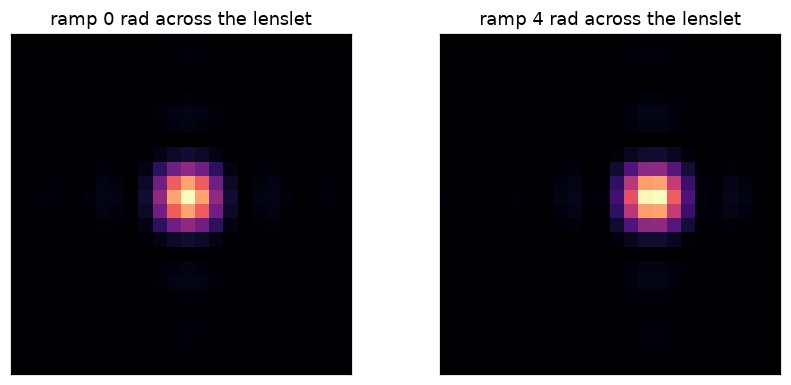

In [2]:
D, N, N_LENSLETS, PAD = 1.0, 128, 8, 4
X, Y, rho, theta, pupil, dx = make_pupil_grid(N=N, diameter=D)
centers, masks = subaperture_masks(X, Y, pupil, n_lenslets=N_LENSLETS, min_fill=0.5)

# A fully illuminated sub-aperture near the pupil centre.
full = [i for i, m in enumerate(masks) if m.sum() == max(mm.sum() for mm in masks)]
k = min(full, key=lambda i: np.hypot(*centers[i]))
lenslet = masks[k]
n_pix = int(lenslet.any(axis=0).sum())
d = n_pix * dx
print(f"Sub-aperture: {n_pix} x {n_pix} pupil samples, d = {d * 100:.1f} cm; lambda/d = {PAD} detector pixels")


def ramp(delta_phi):
    # Phase ramp of delta_phi radians across the sub-aperture, along x.
    return delta_phi * (X - centers[k][0]) / d


spot0 = lenslet_spot_from_phase(np.zeros_like(X), lenslet, pad_factor=PAD)
reference = centroid(spot0)
print("\nramp across d [rad]   predicted shift [px]   measured shift [px]")
for delta_phi in [0.5, 1.0, 2.0, 4.0]:
    measured = centroid(lenslet_spot_from_phase(ramp(delta_phi), lenslet, pad_factor=PAD))[0] - reference[0]
    print(f"{delta_phi:19.1f} {PAD * delta_phi / (2 * np.pi):22.3f} {measured:21.3f}")

fig, axes = plt.subplots(1, 2, figsize=(8, 3.6))
for ax, delta_phi in zip(axes, [0.0, 4.0]):
    spot = crop_center(lenslet_spot_from_phase(ramp(delta_phi), lenslet, pad_factor=PAD), 24)
    ax.imshow(spot, origin="lower", cmap="magma")
    ax.set_title(f"ramp {delta_phi:.0f} rad across the lenslet")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
plt.tight_layout()
plt.show()

## 2. A finite detector window makes the response nonlinear

Each lenslet only has a small patch of detector pixels. Once the spot approaches the edge of its window, part of it is cut off and the centre of gravity is pulled back toward the centre: the sensor saturates. This sets the dynamic range of the sensor.

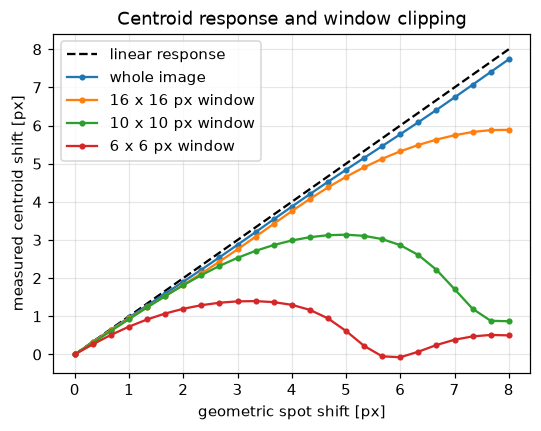

In [3]:
ramps = np.linspace(0, 4 * np.pi, 25)
predicted = PAD * ramps / (2 * np.pi)
fig, ax = plt.subplots(figsize=(5.6, 4))
ax.plot(predicted, predicted, "k--", label="linear response")
for window in [None, 16, 10, 6]:
    ref = centroid(crop_center(spot0, window))[0]
    measured = [centroid(crop_center(lenslet_spot_from_phase(ramp(p), lenslet, pad_factor=PAD), window))[0] - ref for p in ramps]
    ax.plot(predicted, measured, "o-", ms=3, label="whole image" if window is None else f"{window} x {window} px window")
ax.set(xlabel="geometric spot shift [px]", ylabel="measured centroid shift [px]", title="Centroid response and window clipping")
ax.legend()
plt.show()

## 3. Check: photon and read noise

For a centre-of-gravity estimate $\hat{x} = \sum_i x_i n_i / \sum_i n_i$ with expected counts $e_i$, error propagation gives

$$\sigma_{\hat{x}}^2 = \frac{\sum_i e_i (x_i - \bar{x})^2}{E^2} + \sigma_r^2\,\frac{\sum_i (x_i - \bar{x})^2}{E^2}, \qquad E = \sum_i e_i .$$

The first term is photon noise and falls as $1/E$; the second is read noise $\sigma_r$ per pixel, falls as $1/E^2$, and grows with the number of pixels in the window. Below, both are compared with 3000 simulated frames per flux level (negative pixels kept, no threshold). The formula is a linear expansion, so it needs enough flux that the total signal is never close to zero.

read noise   photons   predicted sigma [px]   simulated sigma [px]


       0 e       300                 0.1004                 0.1014


       0 e      1000                 0.0550                 0.0552


       0 e      3000                 0.0318                 0.0323


       0 e     10000                 0.0174                 0.0177


...

       3 e       300                 0.4905                 0.5161


       3 e      1000                 0.1542                 0.1592


       3 e      3000                 0.0576                 0.0581


       3 e     10000                 0.0226                 0.0228


       3 e     30000                 0.0111                 0.0110


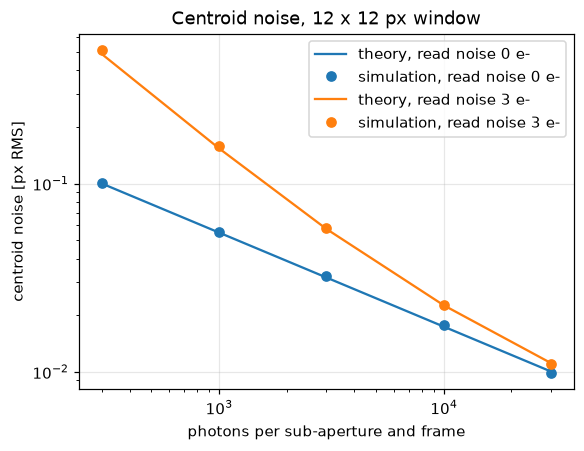

In [4]:
WINDOW = 12
spot = crop_center(spot0, WINDOW)
x = np.arange(WINDOW) - (WINDOW - 1) / 2.0
x_offsets = (x[None, :] - centroid(spot)[0]) ** 2 * np.ones((WINDOW, 1))
photon_levels = np.array([300, 1000, 3000, 10000, 30000])

fig, ax = plt.subplots(figsize=(5.8, 4.2))
print("read noise   photons   predicted sigma [px]   simulated sigma [px]")
for read_noise, color in [(0.0, "C0"), (3.0, "C1")]:
    predicted, simulated = [], []
    for photons in photon_levels:
        expected = photons * spot
        E = expected.sum()
        predicted.append(np.sqrt((np.sum(expected * x_offsets) + read_noise**2 * np.sum(x_offsets)) / E**2))
        draws = [
            centroid(add_detector_noise(spot, photons=photons, read_noise_e=read_noise, seed=s, clip_negative=False))[0]
            for s in range(3000)
        ]
        simulated.append(np.std(draws))
        print(f"{read_noise:8.0f} e {photons:9d} {predicted[-1]:22.4f} {simulated[-1]:22.4f}")
    ax.loglog(photon_levels, predicted, "-", color=color, label=f"theory, read noise {read_noise:.0f} e-")
    ax.loglog(photon_levels, simulated, "o", color=color, label=f"simulation, read noise {read_noise:.0f} e-")
ax.set(xlabel="photons per sub-aperture and frame", ylabel="centroid noise [px RMS]", title=f"Centroid noise, {WINDOW} x {WINDOW} px window")
ax.legend()
fig.savefig(FIGURES / "04_centroid_noise.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Thresholds and calibration

A threshold (set pixels below a fraction of the peak to zero) suppresses read noise in the wings, but it makes the centroid nonlinear and slightly biased. It also affects calibration: with a very small push–pull poke, part of the measured response comes from pixels crossing the threshold rather than from the spot moving. The table reconstructs a known 14-mode wavefront (0.29 rad RMS) without noise. On this grid the larger poke helps only a little; in the archived notebook 06, on a finer 256-sample grid, the 1e-3 rad poke gave a condition number of 23 and a 0.14 rad residual.

In [5]:
modes = generate_zernike_modes(rho, theta, pupil, max_radial_order=4)
true_coeffs = {"Z2_+0": 0.25, "Z2_+2": 0.12, "Z3_+1": 0.08, "Z3_-1": -0.05}
wavefront = synthesize_wavefront(modes, true_coeffs, pupil)

print("threshold   poke [rad]   condition number   residual [rad]")
for threshold, poke in [(0.0, 1e-3), (0.05, 1e-3), (0.05, 0.05)]:
    A_det, names, c, m, ref = build_detector_response_matrix(
        modes, pupil, X, Y, n_lenslets=N_LENSLETS, pad_factor=PAD, threshold_fraction=threshold, calibration_amplitude=poke
    )
    _, shifts = measure_centroid_shifts(
        wavefront, pupil, X, Y, n_lenslets=N_LENSLETS, pad_factor=PAD, threshold_fraction=threshold, reference=ref, masks=m, centers=c
    )
    coeffs, *_ = reconstruct_from_centroid_shifts(shifts, A_det)
    residual = residual_wavefront(wavefront, synthesize_from_coefficients(coeffs, modes, names, pupil), pupil)
    print(f"{threshold:9.2f} {poke:12.0e} {np.linalg.cond(A_det):18.1f} {rms(residual, pupil):16.4f}")

threshold   poke [rad]   condition number   residual [rad]


     0.00        1e-03                5.3           0.0012


     0.05        1e-03                5.1           0.0532


     0.05        5e-02                5.7           0.0425


## 5. Reconstruction against flux

Finally the whole detector chain — thresholded centroids, 3 e⁻ read noise, the 0.05 rad calibration — reconstructs the same wavefront at decreasing photon counts, averaged over 8 noise draws per level.

In [6]:
A_det, names, c, m, ref = build_detector_response_matrix(
    modes, pupil, X, Y, n_lenslets=N_LENSLETS, pad_factor=PAD, threshold_fraction=0.05, calibration_amplitude=0.05
)
scan = centroid_noise_scan(
    wavefront, A_det, modes, names, pupil, X, Y, photon_levels=[1e6, 1e5, 3e4, 1e4, 3e3, 1e3],
    n_lenslets=N_LENSLETS, pad_factor=PAD, read_noise_e=3.0, threshold_fraction=0.05, n_trials=8, seed=5,
)
for photons, stats in scan.items():
    print(f"{photons:9.0f} photons: residual {stats['mean_residual_rms']:.3f} ± {stats['std_residual_rms']:.3f} rad")

  1000000 photons: residual 0.044 ± 0.001 rad
   100000 photons: residual 0.051 ± 0.003 rad
    30000 photons: residual 0.054 ± 0.006 rad
    10000 photons: residual 0.058 ± 0.007 rad
     3000 photons: residual 0.206 ± 0.058 rad
     1000 photons: residual 1.829 ± 0.241 rad


## Summary

- With `pad_factor = 4`, $\lambda/d$ spans 4 pixels, and a phase ramp moves the spot by the shift-theorem amount to within 1–5%.
- A finite window clips the spot and saturates the response, so the window size sets the sensor's dynamic range.
- The centroid noise follows error propagation: within 2% for photon noise alone (falling as $1/\sqrt{N}$), and within 6% with 3 e⁻ read noise, which dominates below about 5000 photons in a 12 × 12 pixel window (falling as $1/N$).
- A 5% threshold costs accuracy even without noise: about 0.05 rad residual instead of 0.001 rad.
- With noise, the reconstruction holds its 0.044 rad floor down to about $10^4$ photons per sub-aperture, degrades to 0.21 rad at 3000 and fails at 1000.